In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris



iris = load_iris()

print("Iris dataset loaded successfully!")



df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["target"] = iris.target

# Add species name
df["species"] = df["target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})



print("\n" + "=" * 50)
print("FIRST 5 ROWS")
print("=" * 50)

print(df.head())



print("\n" + "=" * 50)
print("DATASET INFORMATION")
print("=" * 50)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()



print("\n" + "=" * 50)
print("NULL / MISSING VALUES")
print("=" * 50)

print(df.isnull().sum())




df = df.dropna()

print("\nAfter removing null values:")
print("Number of rows:", df.shape[0])



print("\n" + "=" * 50)
print("DUPLICATE VALUES")
print("=" * 50)

print("Number of duplicate rows:",
      df.duplicated().sum())




df = df.drop_duplicates()

print("\nAfter removing duplicates:")
print("Number of rows:", df.shape[0])


print("\n" + "=" * 50)
print("STATISTICAL SUMMARY")
print("=" * 50)

print(df.describe())

Iris dataset loaded successfully!

FIRST 5 ROWS
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  

DATASET INFORMATION
Number of rows: 150
Number of columns: 6

Column names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target', 'species'],
      dtype='object')

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target     

In [ ]:
X = df[iris.feature_names]
y = df["target"]

print("\n" + "=" * 50)
print("FEATURES AND TARGET")
print("=" * 50)

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())



from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 50)
print("TRAIN / TEST SPLIT")
print("=" * 50)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)



from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

print("\n" + "=" * 50)
print("FEATURE SCALING")
print("=" * 50)

print("Feature scaling completed successfully!")

print("\nFirst 5 scaled training samples:")
print(X_train_scaled[:5])


FEATURES AND TARGET
Features (X):
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target (y):
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

TRAIN / TEST SPLIT
Training samples: 119
Testing samples: 30

X_train shape: (119, 4)
X_test shape: (30, 4)
y_train shape: (119,)
y_test shape: (30,)

FEATURE SCALING
Feature scaling completed successfully!

First 5 scaled training samples:
[[-1.50158712  0.7690314  -1.33909259 -1.17973677]
 [ 0.63982407 -0.58674247  1.04183404  1.1863645 ]
 [-0.19294695 -0.13481785  0.24819183  0.00331387]
 [-0.90675068  1.67288064 -1.05564894 -

Logistic Regression
-------------------
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


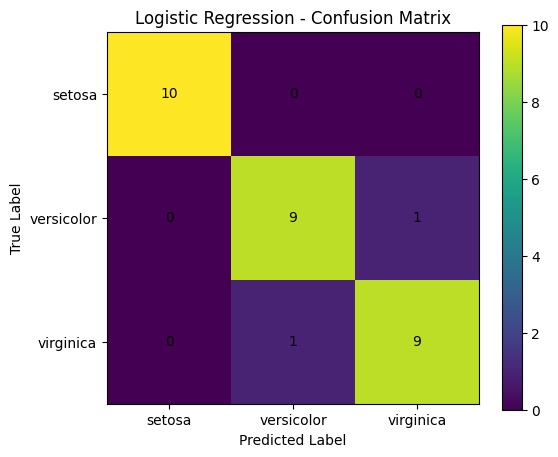

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Create the Logistic Regression model
logistic_model = LogisticRegression(random_state=42)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr = logistic_model.predict(X_test_scaled)

# Calculate accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression")
print("-------------------")
print("Accuracy:", accuracy_lr)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=iris.target_names
))

# Confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm_lr)

# Display confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm_lr)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

# Add values inside the matrix
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm_lr[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

Support Vector Machine (SVM)
----------------------------
Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


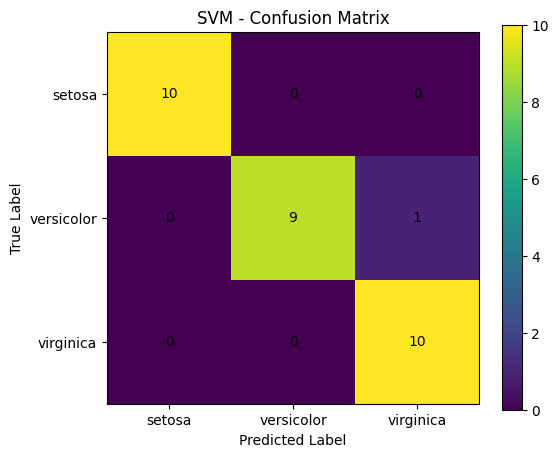

In [ ]:
# ==============================
# MODEL 2: SUPPORT VECTOR MACHINE
# ==============================

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Create the SVM model
svm_model = SVC(kernel="rbf", random_state=42)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_scaled)

# Calculate accuracy
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("Support Vector Machine (SVM)")
print("----------------------------")
print("Accuracy:", accuracy_svm)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=iris.target_names
))

# Confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

print("Confusion Matrix:")
print(cm_svm)

# Display confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm_svm)
plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

# Add values inside the matrix
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm_svm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

Decision Tree
-------------
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


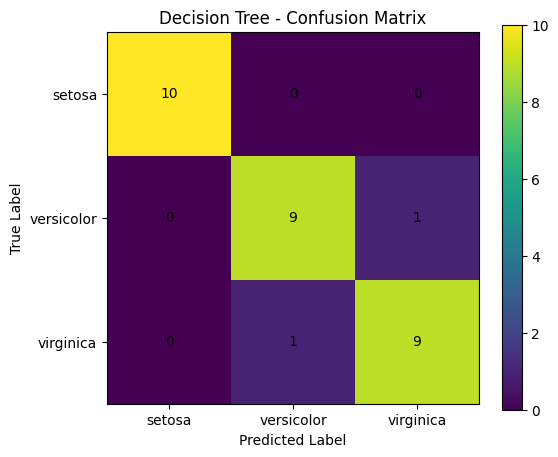

In [ ]:
# ==============================
# MODEL 3: DECISION TREE
# ==============================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree")
print("-------------")
print("Accuracy:", accuracy_dt)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=iris.target_names
))

# Confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Confusion Matrix:")
print(cm_dt)

# Display confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm_dt)
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm_dt[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

Random Forest
-------------
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


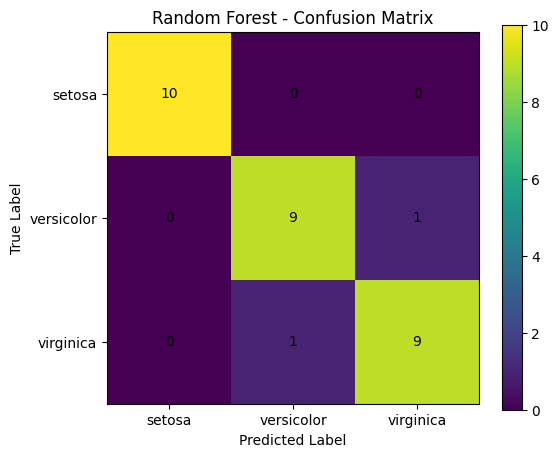

In [ ]:
# ==============================
# MODEL 4: RANDOM FOREST
# ==============================

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest")
print("-------------")
print("Accuracy:", accuracy_rf)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=iris.target_names
))

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm_rf)

# Display confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm_rf)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm_rf[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

Naive Bayes
-----------
Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


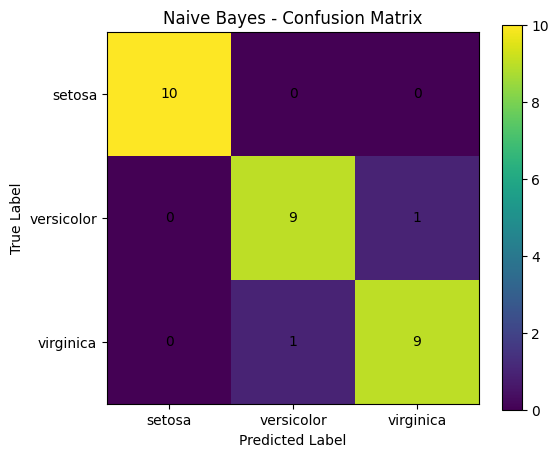

In [ ]:
# ==============================
# MODEL 5: NAIVE BAYES
# ==============================

from sklearn.naive_bayes import GaussianNB

# Create the Gaussian Naive Bayes model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)

# Calculate accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes")
print("-----------")
print("Accuracy:", accuracy_nb)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=iris.target_names
))

# Confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

print("Confusion Matrix:")
print(cm_nb)

# Display confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm_nb)
plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm_nb[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

Neural Network (MLP)
--------------------
Accuracy: 0.9666666666666667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


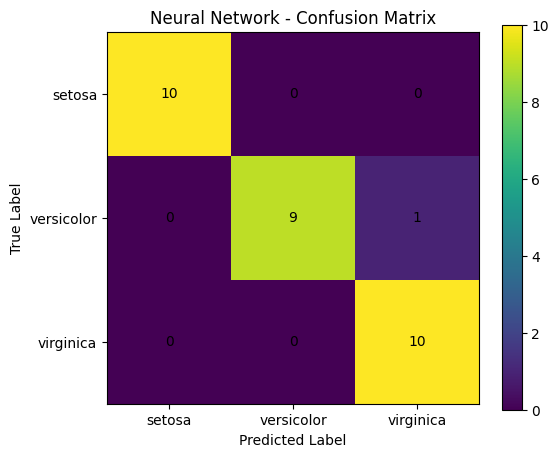

In [ ]:
# ==============================
# MODEL 6: NEURAL NETWORK (MLP)
# ==============================

from sklearn.neural_network import MLPClassifier

# Create the Neural Network model
nn_model = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)

# Train the model using scaled features
nn_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_nn = nn_model.predict(X_test_scaled)

# Calculate accuracy
accuracy_nn = accuracy_score(y_test, y_pred_nn)

print("Neural Network (MLP)")
print("--------------------")
print("Accuracy:", accuracy_nn)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nn,
    target_names=iris.target_names
))

# Confusion matrix
cm_nn = confusion_matrix(y_test, y_pred_nn)

print("Confusion Matrix:")
print(cm_nn)

# Display confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm_nn)
plt.title("Neural Network - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm_nn[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9333     0.9333  0.9333    0.9333
                SVM    0.9667     0.9697  0.9667    0.9666
      Decision Tree    0.9333     0.9333  0.9333    0.9333
      Random Forest    0.9333     0.9333  0.9333    0.9333
        Naive Bayes    0.9333     0.9333  0.9333    0.9333
     Neural Network    0.9667     0.9697  0.9667    0.9666

BEST MODEL
Model: SVM
Accuracy: 0.9667


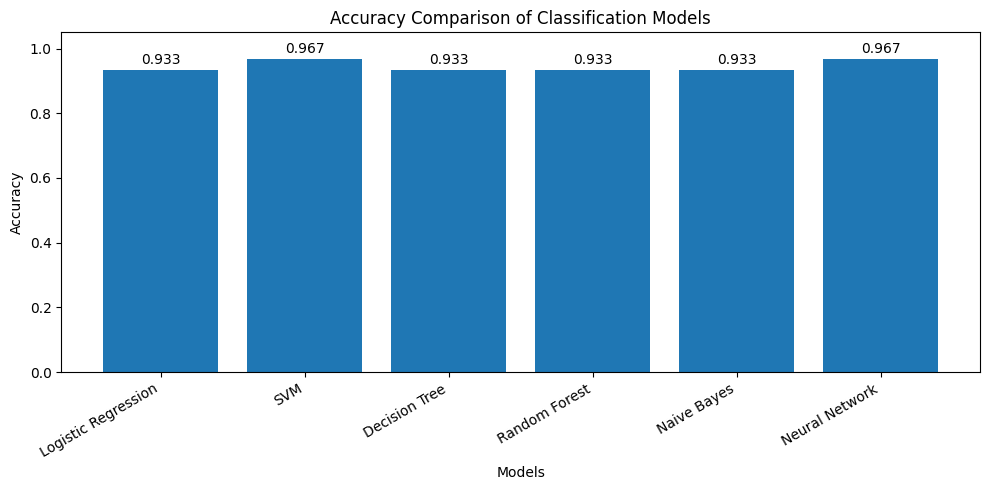

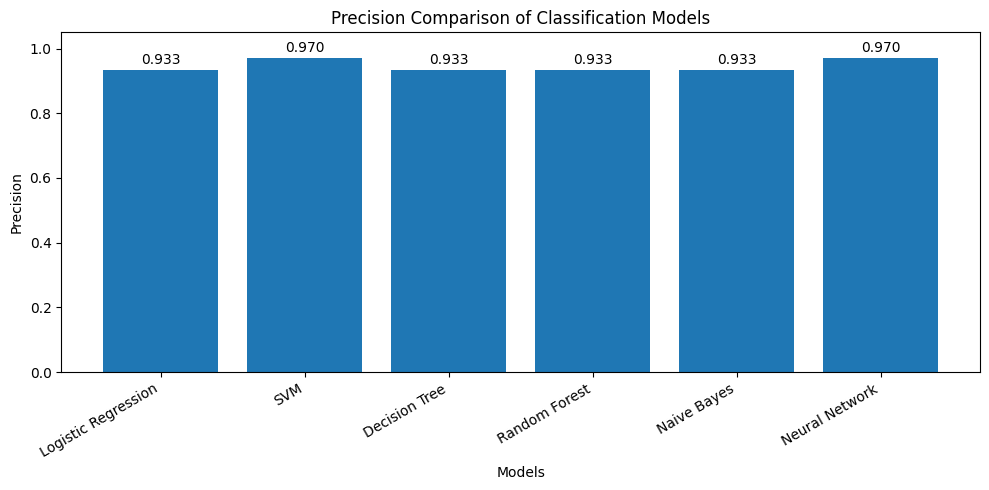

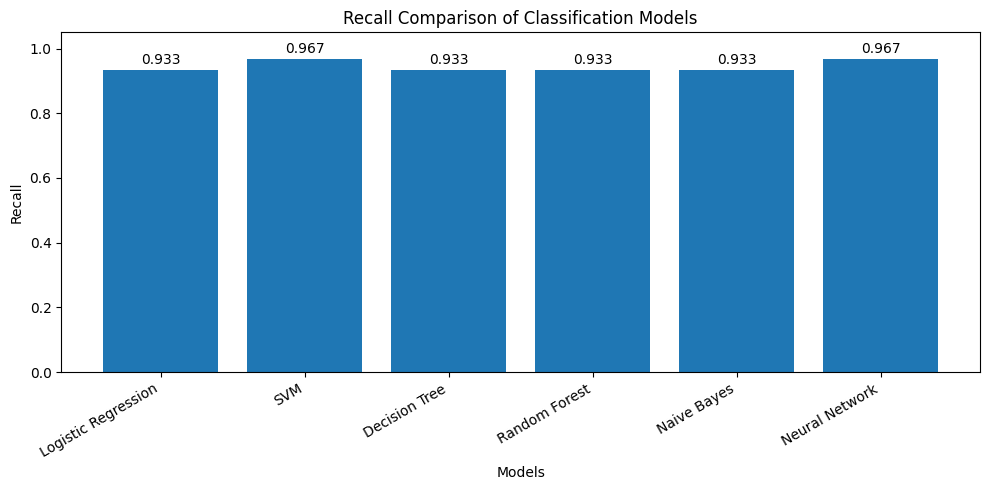

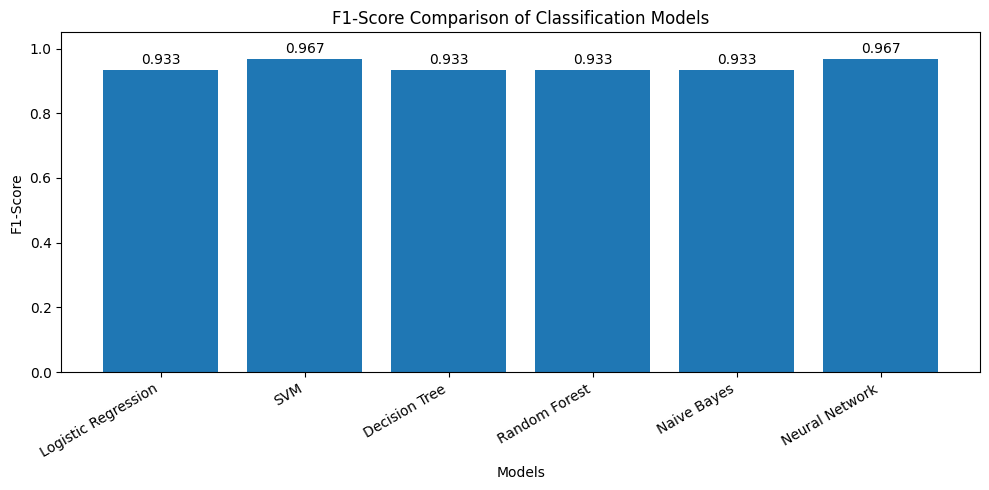

In [ ]:
# ============================================
# FINAL COMPARISON OF ALL 6 MODELS
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import matplotlib.pyplot as plt


# 1. STORE ALL MODEL PREDICTIONS

models = {
    "Logistic Regression": y_pred_lr,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Naive Bayes": y_pred_nb,
    "Neural Network": y_pred_nn
}


# 2. CALCULATE METRICS

results = []

for model_name, y_pred in models.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted"
        )
    })


comparison_df = pd.DataFrame(results)


# 3. DISPLAY COMPARISON TABLE

print("============================================")
print("FINAL MODEL COMPARISON")
print("============================================")

print(comparison_df.round(4).to_string(index=False))


# 4. FIND BEST MODEL

best_model = comparison_df.loc[
    comparison_df["Accuracy"].idxmax()
]

print("\n============================================")
print("BEST MODEL")
print("============================================")

print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))


# ============================================
# 5. ACCURACY COMPARISON GRAPH
# ============================================

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Accuracy Comparison of Classification Models")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)

for i, value in enumerate(comparison_df["Accuracy"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================
# 6. PRECISION COMPARISON GRAPH
# ============================================

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Precision"]
)

plt.title("Precision Comparison of Classification Models")
plt.xlabel("Models")
plt.ylabel("Precision")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)

for i, value in enumerate(comparison_df["Precision"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================
# 7. RECALL COMPARISON GRAPH
# ============================================

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Recall"]
)

plt.title("Recall Comparison of Classification Models")
plt.xlabel("Models")
plt.ylabel("Recall")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)

for i, value in enumerate(comparison_df["Recall"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================
# 8. F1-SCORE COMPARISON GRAPH
# ============================================

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["F1-Score"]
)

plt.title("F1-Score Comparison of Classification Models")
plt.xlabel("Models")
plt.ylabel("F1-Score")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)

for i, value in enumerate(comparison_df["F1-Score"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()